In [20]:
import numpy as np
import matplotlib.pyplot as plt

1. Name：Ran Lu
2. Name：Xiaomeng Li
3. Name：Alizée XIA

## Linear Classification with gradient descent

### Exercise 1
The objective of this exercise is to build a simple linear classifier on a linearly separable problem. To this end we propose a toy dataset generated according to two gaussian (one class by gaussian).

In [21]:
np.random.seed(42)
dataset = list(zip(np.random.randn(50,2)*0.2 + [0.5, -0.5], np.ones(50))) \
               + list(zip(np.random.randn(50,2)*0.4 + [-0.5, 0.5], np.zeros(50)))
X, Y = np.array([x for (x, _) in dataset]), np.array([y for (_, y) in dataset]) 

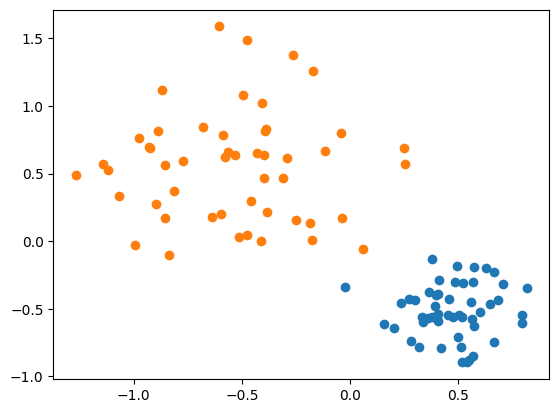

In [22]:
plt.scatter(X[Y==1][:, 0],X[Y==1][:, 1])
plt.scatter(X[Y==0][:, 0],X[Y==0][:, 1])

## 1. Linear Function and loss 
**Question 1**:Create a function `affine` taking as parameters $w$ (2 dim vector), $b$ (scalars) and $x$ (2 dim vector) that return $$w^{\intercal}x  + b$$ 


In [23]:
def affine(w, b, x):
    return np.dot(w, x) + b
    raise NotImplementedError('Implement the function')

**Question 2:** Compute the equation of the line  such that $w^{\intercal}x  + b = 0$ and then draw it for $w_1 = 1$, $w_2 = 2$ and $b=1$. The function should return parameters $c$ and $d$ of $y = cx + d$

-0.5 -0.5


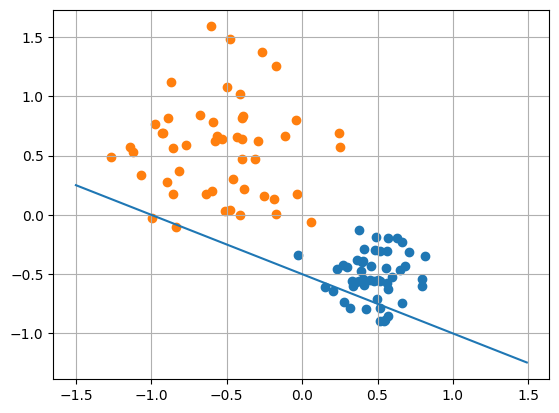

In [24]:
def line_param(w, b):
    c = -w[0] / w[1]
    d = -b / w[1]

    return c, d
    raise NotImplementedError('Implement the function')
c, d = line_param([1, 2], 1)
print(d, c)
plt.scatter(X[Y==1][:, 0],X[Y==1][:, 1])
plt.scatter(X[Y==0][:, 0],X[Y==0][:, 1])
plt.grid()
rrange = np.arange(-1.5, 1.5, 0.01)
plt.plot(rrange, rrange * c + d)
plt.show()

**Question 3**: Create a function `affine_grad` taking as parameters $w$ (2 dim vector), $b$ (scalars) and $x$ (2 dim vector) returning the gradient w.r.t $w$ and $b$ : $$(\nabla_{w}w^{\intercal}x  + b,\nabla_{b}w^{\intercal}x  + b) $$ 

In [25]:
def affine_grad(w, b, x):

    return x, 1
    raise NotImplementedError('Implement the function')

## Hinge loss: forward and gradient
Create two functions that compute respectivelly the Hinge Loss and its derivative (in x) .

$$\text{Hinge loss} = \max(0, 1 - y \times x)$$

!!! This is the formula of the hinge loss if $y\in \{-1,1\}$

In [26]:
def hinge_loss(x, y):
    return max(0, 1 - y * x)
    raise NotImplementedError('Implement the function')

def hinge_loss_grad(x, y):
        if y * x >= 1:
            return 0
        else:
            return -y

# raise NotImplementedError('Implement the function')

## 2. Gradient descent


Consider the function $f_{w, b}$ such that $f_{w, b}(x) = \max(0, 1 - y \times (w^{\intercal}x  + b))$. We want to train such function using SGD on parameters (w,b). 

**Question 1**: Complete the training loop below:


The loss for the epoch 0 is 0.9767277143281154


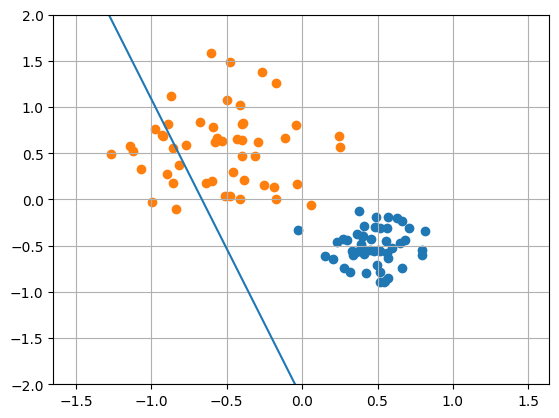

The loss for the epoch 1 is 0.9225269439658333


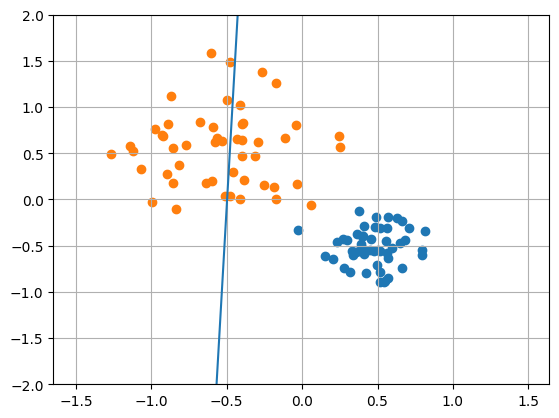

The loss for the epoch 2 is 0.8683261736035515


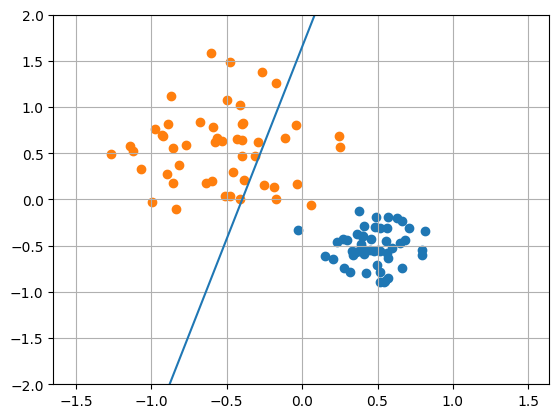

The loss for the epoch 3 is 0.8141254032412694


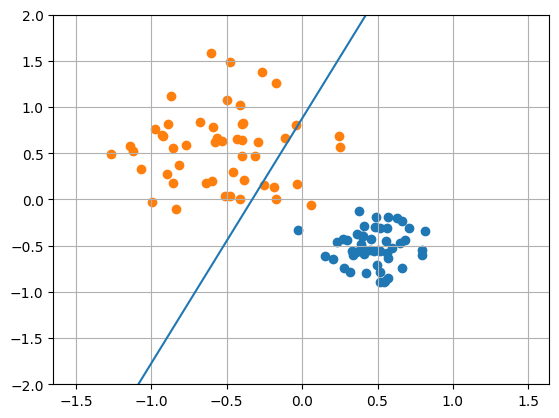

The loss for the epoch 4 is 0.7599246328789871


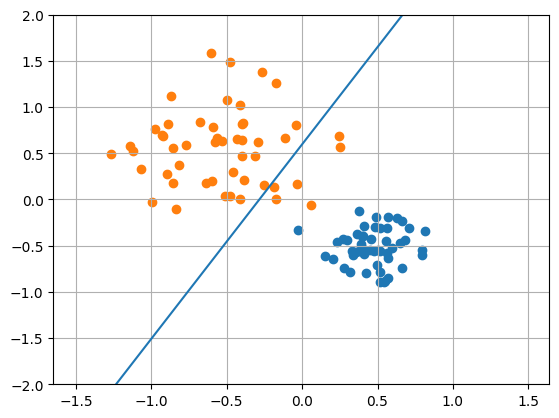

The loss for the epoch 5 is 0.7057238625167048


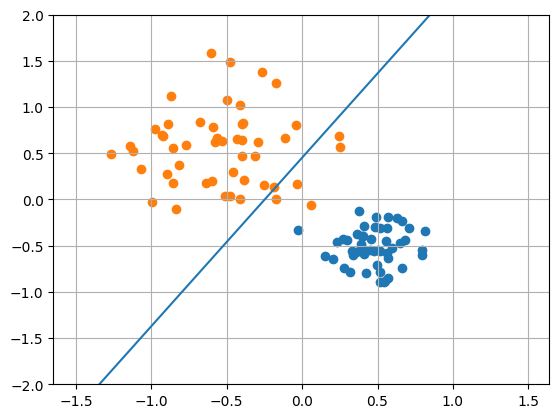

The loss for the epoch 6 is 0.6515230921544227


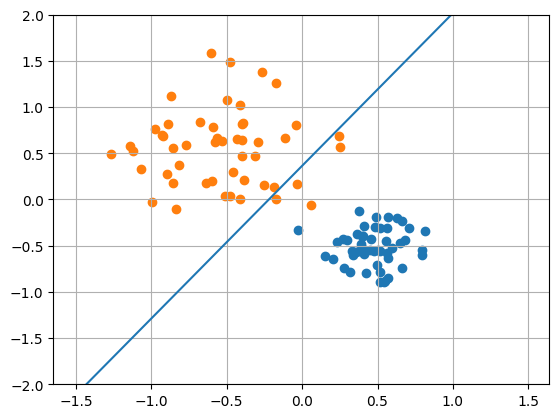

The loss for the epoch 7 is 0.5973223217921406


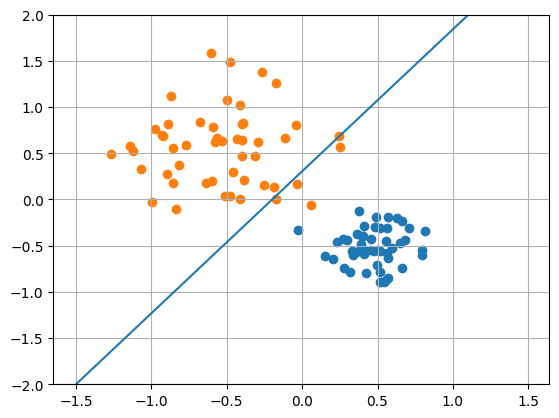

The loss for the epoch 8 is 0.5431215514298584


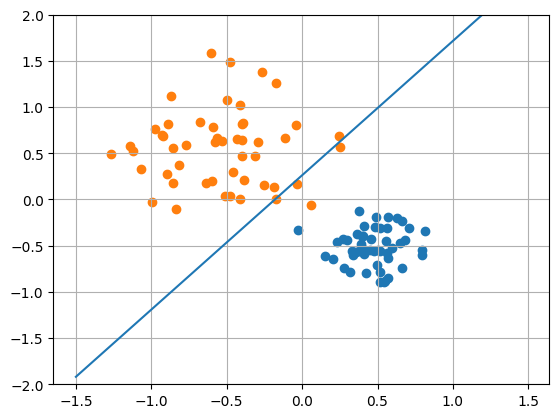

The loss for the epoch 9 is 0.48892078106757614


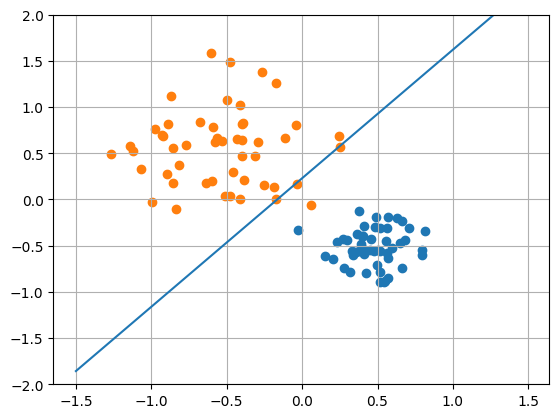

The loss for the epoch 10 is 0.43552130350528556


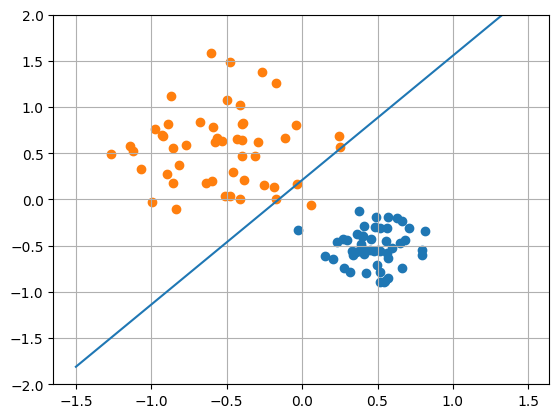

The loss for the epoch 11 is 0.38605217359808164


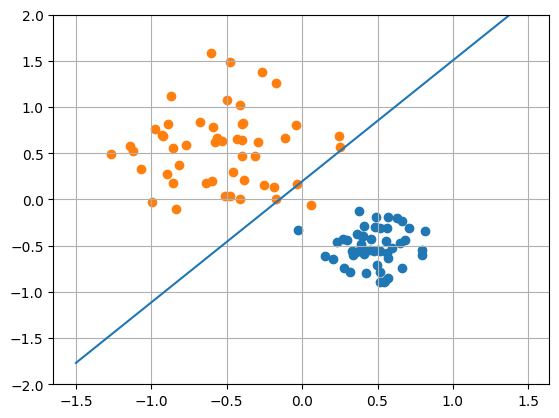

The loss for the epoch 12 is 0.34072217434580315


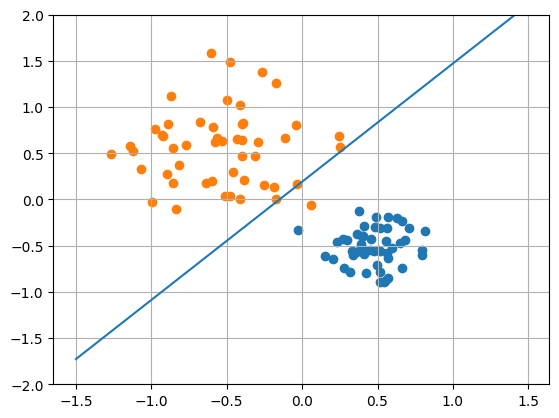

The loss for the epoch 13 is 0.30660907695100154


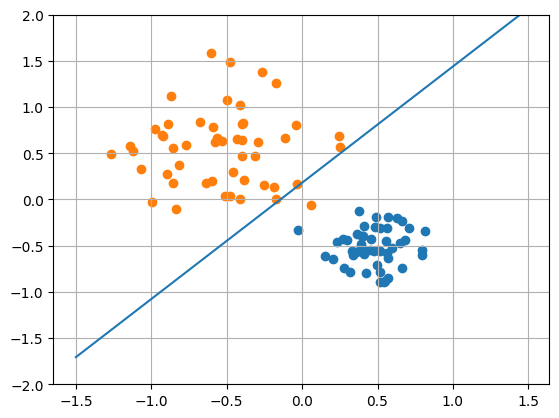

The loss for the epoch 14 is 0.27764802051234605


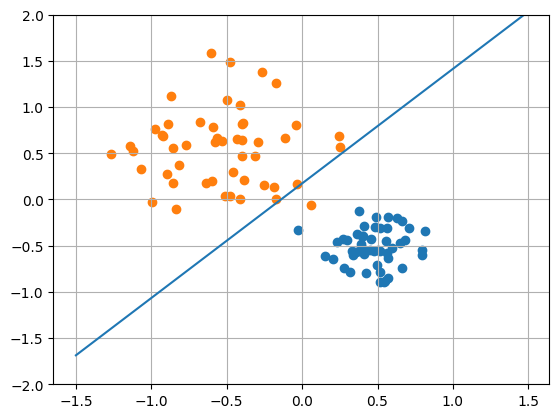

The loss for the epoch 15 is 0.2529987759040676


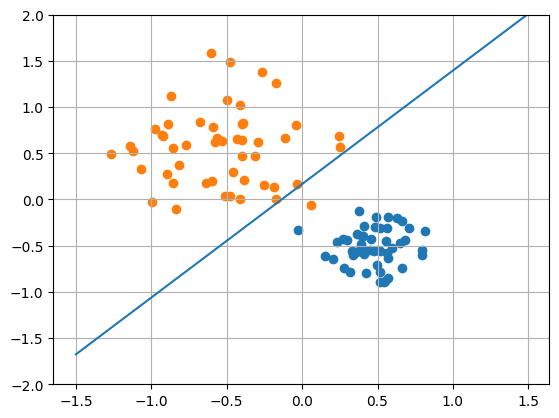

The loss for the epoch 16 is 0.23370856407961682


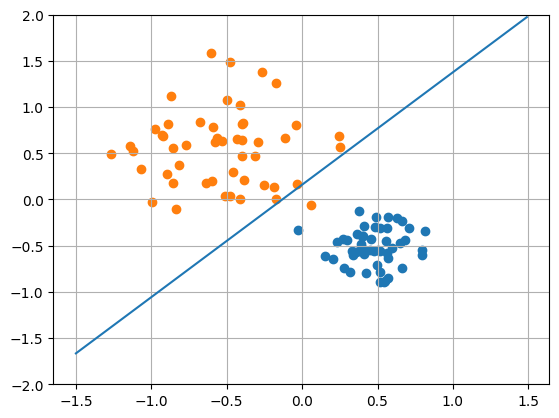

The loss for the epoch 17 is 0.2173276028718342


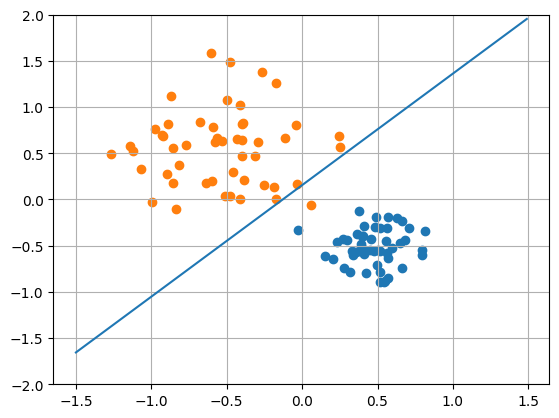

The loss for the epoch 18 is 0.20355961095814123


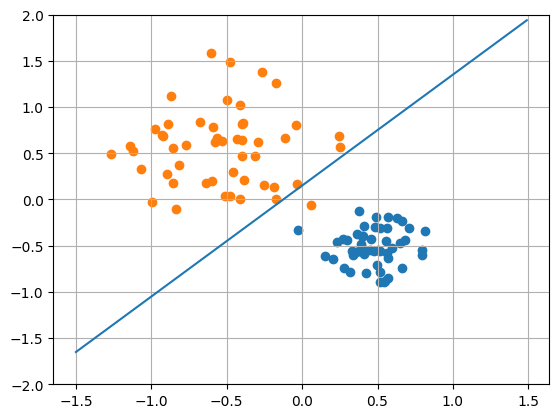

The loss for the epoch 19 is 0.1920464896660074


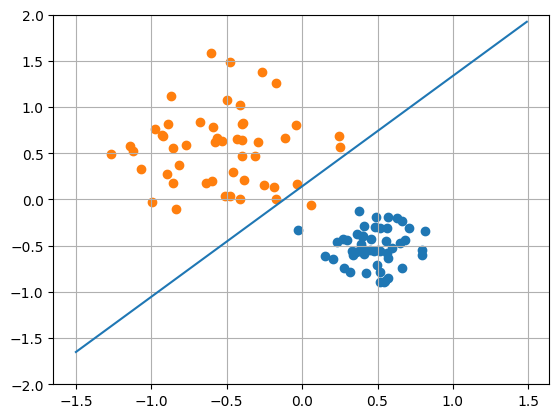

In [28]:
n_epoch = 20
w = [0.1, 0.1]
b = 0.1
learning_rate = 1e-3

for epoch in range(n_epoch):
    loss_values = []
    shuffled_index = np.arange(len(X))
    np.random.shuffle(shuffled_index)
    
    for i in shuffled_index:
        x, y_0 = X[i], Y[i]
        y  = np.where(y_0 == 0, -1, 1) 
        # raise NotImplementedError('Implement the function')
    
        o_pred = affine(w, b, x)
        loss = hinge_loss(o_pred, y)
        loss_values.append(loss)
        
        loss_grad = hinge_loss_grad(o_pred, y)
         
        w_grad = loss_grad * x  
        b_grad = loss_grad

        # update w and b according to the gradients
        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad
    print(f'The loss for the epoch {epoch} is {np.mean(loss_values)}')
    loss_values = []

    c, d = line_param(w, b)
    
    plt.scatter(X[Y==1][:, 0],X[Y==1][:, 1])
    plt.scatter(X[Y==0][:, 0],X[Y==0][:, 1])
    plt.grid()
    rrange = np.arange(-1.5, 1.5, 0.01)
    plt.plot(rrange, rrange * c + d)
    plt.ylim([-2, 2])
    
    plt.show()
    

**Question 2** Compute the final accuracy (number of correct classification on number of data points)

In [29]:
preds = (np.dot(X, w) + b) > 0
accuracy = np.mean(preds == Y)
print(f"Final Accuracy: {accuracy * 100:.2f}%")

Final Accuracy: 99.00%


**Question 3** With minimal changes (hyper-parameters) can you improve accuracy? If yes, apply those changes.

In [34]:
n_epoch = 200              
w = [0.1, 0.1]              
b = 0.1
learning_rate = 0.1   

for epoch in range(n_epoch):
    loss_values = []
    shuffled_index = np.arange(len(X))
    np.random.shuffle(shuffled_index)
    
    for i in shuffled_index:
        x, y_0 = X[i], Y[i]
        y = np.where(y_0 == 0, -1, 1)   
        

        o_pred = affine(w, b, x)
        loss = hinge_loss(o_pred, y)
        loss_values.append(loss)
        
        loss_grad = hinge_loss_grad(o_pred, y)
        w_grad = loss_grad * x           
        b_grad = loss_grad
    
        w = w - learning_rate * w_grad
        b = b - learning_rate * b_grad
    
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, mean loss: {np.mean(loss_values):.4f}')

Epoch 0, mean loss: 0.1892
Epoch 10, mean loss: 0.0200
Epoch 20, mean loss: 0.0165
Epoch 30, mean loss: 0.0146
Epoch 40, mean loss: 0.0136
Epoch 50, mean loss: 0.0128
Epoch 60, mean loss: 0.0119
Epoch 70, mean loss: 0.0111
Epoch 80, mean loss: 0.0104
Epoch 90, mean loss: 0.0098
Epoch 100, mean loss: 0.0090
Epoch 110, mean loss: 0.0084
Epoch 120, mean loss: 0.0082
Epoch 130, mean loss: 0.0077
Epoch 140, mean loss: 0.0073
Epoch 150, mean loss: 0.0069
Epoch 160, mean loss: 0.0066
Epoch 170, mean loss: 0.0060
Epoch 180, mean loss: 0.0065
Epoch 190, mean loss: 0.0056


## 3. Non linearly separable problem

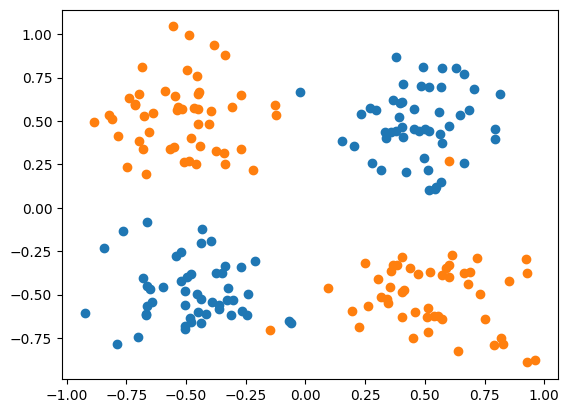

In [42]:
np.random.seed(42)
dataset = list(zip(np.random.randn(50,2)*0.2 + [0.5, 0.5], np.ones(50))) \
               + list(zip(np.random.randn(50,2)*0.2 + [-0.5, 0.5], np.zeros(50)))\
               + list(zip(np.random.randn(50,2)*0.2 + [0.5, -0.5], np.zeros(50))) \
               +  list(zip(np.random.randn(50,2)*0.2 + [-0.5, -0.5], np.ones(50)))
X, Y = np.array([x for (x, _) in dataset]), np.array([y for (_, y) in dataset]) 

plt.scatter(X[Y==1][:, 0],X[Y==1][:, 1])
plt.scatter(X[Y==0][:, 0],X[Y==0][:, 1])

**Question 1**: Train a linear classifier on this dataset and reports the results. Without manually transform the data explain what architecture could solve this problem

In [43]:
w = [0.1, 0.1]
b = 0.1
learning_rate = 0.01
n_epoch = 50

for epoch in range(n_epoch):
    loss_values = []
    shuffled_index = np.arange(len(X))
    np.random.shuffle(shuffled_index)
    
    for i in shuffled_index:
        x, y_0 = X[i], Y[i]
        y = np.where(y_0 == 0, -1, 1)
        
        o_pred = affine(w, b, x)
        loss = hinge_loss(o_pred, y)
        loss_values.append(loss)
        
        loss_grad = hinge_loss_grad(o_pred, y)
        w_grad = loss_grad * x
        b_grad = loss_grad
        
        w -= learning_rate * w_grad
        b -= learning_rate * b_grad
    
    if epoch % 10 == 0:
        print(f'Epoch {epoch}, mean loss: {np.mean(loss_values):.4f}')

preds = (np.dot(X, w) + b) > 0
accuracy = np.mean(preds == Y)
print(f"Final Accuracy: {accuracy * 100:.2f}%")

Epoch 0, mean loss: 1.0087
Epoch 10, mean loss: 1.0078
Epoch 20, mean loss: 1.0069
Epoch 30, mean loss: 1.0060
Epoch 40, mean loss: 1.0051
Final Accuracy: 47.00%


Linear Classifier Performance：

The linear classifier achieves only ~50% accuracy on the four‑cluster dataset.
This is because the data are non‑linearly separable (XOR problem) – a straight line cannot separate the two classes distributed in diagonal clusters.

Architectures That Solve the Problem：

Multilayer Perceptron (MLP) 
 – A single hidden layer with non‑linear activation can learn a representation that makes the data linearly separable in the hidden space.

Kernel SVM 
 – The RBF kernel implicitly maps the data into a higher‑dimensional space where the classes become linearly separable.
 
Both approaches introduce the necessary non‑linearity and can achieve 100% accuracy on this task.